# 03 Gradient boosting: predict the defect of each job

**Goal:** build the **master job table** (one row per job: inputs + defect), train a **gradient boosting** model on it, and test how accurate it is.

**What this model is for in the FYP:** it is the **classical baseline**. It can say *which* defect a job probably has, but not *why*.
Later, the knowledge graph + LLM system has to beat it, or at least match it and also explain the cause.

**Inputs:** `datasets/` (job settings) and `data/processed/event_timeline.csv` (alarms, maintenance, inspections from notebook 01).
**Outputs:** `data/processed/master_job_table.csv` and figures in `data/processed/figures/` for the report.

If `sklearn` is missing, run `pip install scikit-learn` once in the Anaconda Prompt.

## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

DATA = Path("..") / "datasets"
OUT = Path("..") / "data" / "processed"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

tl = pd.read_csv(OUT / "event_timeline.csv")
tl["time"] = pd.to_datetime(tl["time"], format="ISO8601")   # stops with an error if Excel re-saved the file: re-run notebook 01
print(len(tl), "timeline events")

1204 timeline events


## 1. Start from the job log
The timeline only keeps a short `detail` text for each job, so we re-read the job log to get **all** the settings (same cleaning as notebook 01).

In [2]:
jobs = pd.read_csv(DATA / "machine" / "job_log.csv", sep=";", decimal=",").drop_duplicates()
jobs["StartTime"] = pd.to_datetime(jobs["StartTime"], format="%d.%m.%Y %H:%M:%S")
jobs["EndTime"] = pd.to_datetime(jobs["EndTime"], format="%d.%m.%Y %H:%M:%S")
jobs = jobs.sort_values("StartTime").reset_index(drop=True)
print(len(jobs), "jobs")

# 15 jobs have no NozzleOperatingHours. This model can't handle blanks, so we copy the previous job's value
# (the same nozzle was usually still fitted). Write this decision in the report.
print("jobs with missing nozzle hours:", jobs["NozzleOperatingHours"].isna().sum())
jobs["NozzleOperatingHours"] = jobs["NozzleOperatingHours"].ffill()
jobs.head(3)

527 jobs
jobs with missing nozzle hours: 15


,JobID,StartTime,EndTime,ProgramName,Material,Thickness_mm,CuttingGas,LaserPower_W,FeedRate_mm_min,GasPressureSet_bar,FocusPosition_mm,NozzleDiameter_mm,Standoff_mm,BevelAngle_deg,NozzleOperatingHours,PartsOnSheet,Status,Operator
0,JOB-00001,2026-09-01 06:25:00,2026-09-01 07:35:00,S235JR_12mm_BEV,S235JR,12,O2,6000,1520,0.6,4.0,1.4,1.2,22.5,0.0,42,Completed,MR
1,JOB-00002,2026-09-01 07:46:00,2026-09-01 09:15:00,S235JR_12mm,S235JR,12,O2,6000,1540,0.6,4.5,1.4,1.0,0.0,1.3,12,Completed,MR
2,JOB-00003,2026-09-01 09:37:00,2026-09-01 10:51:00,14301_6mm,1.4301,6,N2,6000,3140,18.2,-3.5,2.3,0.8,0.0,3.0,60,Completed,KT


## 2. Add the answer column (the label)
The defect comes from the `inspection` rows of the timeline. Jobs with no inspection, or inspected as `unknown`, have **no answer**, so the model can't learn from them.
`burnt_edge` happens only once, which is too rare to learn, so it's left out too.

In [3]:
insp = tl[tl["event_type"] == "inspection"][["job_id", "detail"]].copy()
insp["defect"] = insp["detail"].str.split(" | ", regex=False).str[1]
jobs = jobs.merge(insp[["job_id", "defect"]], left_on="JobID", right_on="job_id", how="left").drop(columns="job_id")

labelled = jobs["defect"].notna() & ~jobs["defect"].isin(["unknown", "burnt_edge"])
print("jobs with a usable label:", labelled.sum(), "of", len(jobs))
jobs.loc[labelled, "defect"].value_counts()

jobs with a usable label: 401 of 527


defect
ok                 250
dross               51
incomplete_cut      51
rough_cut           37
bevel_deviation     12
Name: count, dtype: int64

## 3. Feature engineering: turn EDA findings into columns
Each cause you found in EDA becomes a column that measures it. **All of them only use information from before or during the job**, never the inspection (that would be cheating, called *leakage*).

| EDA finding | Column |
|---|---|
| dirty protective glass | `hours_since_glass_clean`, `alarms_2105`, `alarms_4001` |
| worn nozzle | `NozzleOperatingHours` (already there) |
| N2 gas supply fault | `alarms_1201` (the job log only has the *set* pressure) |
| head collision | `hours_since_collision`, `alarms_3302`, `is_bevel` |
| `_FAST` programs | `is_fast`, `feed_vs_table` (feed rate ÷ recommended feed) |
| when / who | `late_shift` |

In [4]:
# --- hours since the last glass cleaning (merge_asof = "the last one before") ---
glass = tl[tl["event_type"] == "maintenance_glass"][["time"]].rename(columns={"time": "last_glass"}).sort_values("last_glass")
jobs = pd.merge_asof(jobs, glass, left_on="StartTime", right_on="last_glass", direction="backward")
jobs["hours_since_glass_clean"] = (jobs["StartTime"] - jobs["last_glass"]).dt.total_seconds() / 3600

# --- hours since the last collision alarm (3301); 999 = no collision yet ---
alarms = tl[tl["event_type"] == "alarm"].copy()
alarms["code"] = alarms["detail"].str.split(" ").str[0]
coll = alarms[alarms["code"] == "3301"][["time"]].rename(columns={"time": "last_collision"}).sort_values("last_collision")
jobs = pd.merge_asof(jobs, coll, left_on="StartTime", right_on="last_collision", direction="backward")
jobs["hours_since_collision"] = ((jobs["StartTime"] - jobs["last_collision"]).dt.total_seconds() / 3600).fillna(999)

# --- number of alarms of each code during the job (notebook 01 already linked alarms to jobs) ---
counts = pd.crosstab(alarms["job_id"], alarms["code"]).add_prefix("alarms_")
jobs = jobs.merge(counts, left_on="JobID", right_index=True, how="left")
alarm_cols = list(counts.columns)
jobs[alarm_cols] = jobs[alarm_cols].fillna(0)

# --- feed rate compared with the recommended cutting table ---
table = pd.read_csv(DATA / "documents" / "cutting_table.csv")
table = table.rename(columns={"material": "Material", "gas": "CuttingGas", "thickness_mm": "Thickness_mm", "feed_rate_mm_min": "table_feed"})
jobs = jobs.merge(table[["Material", "CuttingGas", "Thickness_mm", "table_feed"]], on=["Material", "CuttingGas", "Thickness_mm"], how="left")
jobs["feed_vs_table"] = jobs["FeedRate_mm_min"] / jobs["table_feed"]

# --- simple yes/no columns ---
jobs["is_fast"] = jobs["ProgramName"].str.contains("_FAST").astype(int)
jobs["is_bevel"] = (jobs["BevelAngle_deg"] != 0).astype(int)
jobs["late_shift"] = (jobs["StartTime"].dt.hour >= 14).astype(int)

jobs[["JobID", "NozzleOperatingHours", "hours_since_glass_clean", "alarms_2105", "alarms_1201", "feed_vs_table", "is_fast", "defect"]].head()

,JobID,NozzleOperatingHours,hours_since_glass_clean,alarms_2105,alarms_1201,feed_vs_table,is_fast,defect
0,JOB-00001,0.0,0.350000,0.0,0.0,1.013333,0,NaN
1,JOB-00002,1.3,1.700000,0.0,0.0,1.026667,0,ok
2,JOB-00003,3.0,3.550000,0.0,0.0,0.981250,0,NaN
3,JOB-00004,4.5,5.016667,0.0,0.0,1.003846,0,ok
4,JOB-00005,5.5,6.016667,0.0,0.0,1.013333,0,rough_cut


## 4. Turn text into numbers (one-hot encoding)
Models only read numbers. `Material` and `CuttingGas` are text, so each value becomes its own 0/1 column (for example `gas_N2`, `gas_O2`).
Gradient boosting doesn't need the numbers rescaled.

In [5]:
NUMBER_COLS = ["Thickness_mm", "LaserPower_W", "FeedRate_mm_min", "GasPressureSet_bar", "FocusPosition_mm",
               "NozzleDiameter_mm", "Standoff_mm", "BevelAngle_deg", "NozzleOperatingHours", "PartsOnSheet",
               "hours_since_glass_clean", "hours_since_collision", "feed_vs_table",
               "is_fast", "is_bevel", "late_shift"] + alarm_cols

X_all = pd.concat([jobs[NUMBER_COLS],
                   pd.get_dummies(jobs["Material"], prefix="mat", dtype=int),
                   pd.get_dummies(jobs["CuttingGas"], prefix="gas", dtype=int)], axis=1)

master = pd.concat([jobs[["JobID", "StartTime"]], X_all, jobs[["defect"]]], axis=1)
master.to_csv(OUT / "master_job_table.csv", index=False)
print("master job table:", master.shape[0], "rows x", X_all.shape[1], "input columns -> saved")

X = X_all[labelled]
y = jobs.loc[labelled, "defect"]
print("training data:", X.shape)

master job table: 527 rows x 27 input columns -> saved
training data: (401, 27)


## 5. Split: train on 80%, test on the hidden 20%
The model never sees the test jobs while learning, so the test score shows how it does on **new** jobs.
`stratify=y` keeps the same mix of defects in both parts. `random_state=42` makes the split the same every run.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", len(X_train), "jobs | test:", len(X_test), "jobs")

train: 320 jobs | test: 81 jobs


## 6. Train the gradient boosting model
Gradient boosting builds many small decision trees one after another. Each new tree fixes the mistakes of the ones before it.
The three settings below are the usual starting values. Change them later and see if the test score improves.

In [7]:
model = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

## 7. How accurate is it?
- **Accuracy:** the share of test jobs with the right defect.
- **Baseline:** a "model" that always says `ok`. Your model must clearly beat this, or it learned nothing.
- **Macro F1:** the average score over all defect types, so rare defects count as much as `ok`. This is fairer than accuracy when most jobs are ok.

In [8]:
baseline = (y_test == "ok").mean()
print(f"Always-'ok' baseline accuracy : {baseline:.1%}")
print(f"Gradient boosting accuracy    : {accuracy_score(y_test, pred):.1%}")
print(f"Gradient boosting macro F1    : {f1_score(y_test, pred, average='macro'):.2f}")
print()
print(classification_report(y_test, pred, zero_division=0))

Always-'ok' baseline accuracy : 63.0%
Gradient boosting accuracy    : 71.6%
Gradient boosting macro F1    : 0.63

                 precision    recall  f1-score   support

bevel_deviation       1.00      1.00      1.00         2
          dross       0.60      0.60      0.60        10
 incomplete_cut       0.60      0.30      0.40        10
             ok       0.74      0.88      0.80        51
      rough_cut       0.67      0.25      0.36         8

       accuracy                           0.72        81
      macro avg       0.72      0.61      0.63        81
   weighted avg       0.70      0.72      0.69        81



**How to read the report:** for each defect, *precision* = when the model says "dross", how often is it really dross; *recall* = of all real dross jobs, how many did it find.
Low recall on a defect means the model misses it. Then check whether a column for its cause is missing.

### Figure 1: confusion matrix
Rows are the **true** defect, columns are what the model **predicted**. The diagonal is correct. Anything off the diagonal shows which defects get confused with each other.

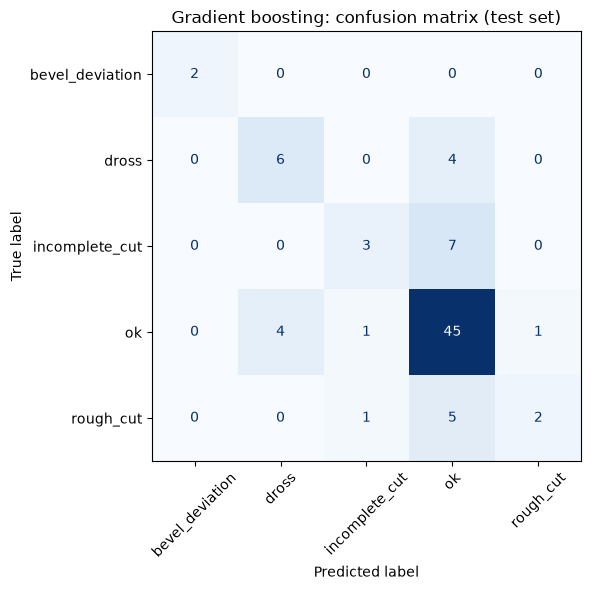

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Gradient boosting: confusion matrix (test set)")
plt.tight_layout()
plt.savefig(FIG / "fig1_confusion_matrix.png", dpi=200)
plt.show()

## 8. Is the score just luck? (5-fold cross-validation)
With only about 80 test jobs, one lucky or unlucky split can change the score a lot.
Cross-validation repeats the train/test split **5 times** with different hidden jobs and reports the average. Report this number (mean ± spread) in your thesis.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = cross_val_score(GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42), X, y, cv=cv, scoring="accuracy")
cv_f1 = cross_val_score(GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42), X, y, cv=cv, scoring="f1_macro")
print("accuracy per fold:", np.round(cv_acc, 2))
print(f"accuracy: {cv_acc.mean():.1%} ± {cv_acc.std():.1%}")
print(f"macro F1: {cv_f1.mean():.2f} ± {cv_f1.std():.2f}")

accuracy per fold: [0.77 0.76 0.79 0.71 0.79]
accuracy: 76.3% ± 2.7%
macro F1: 0.70 ± 0.05


## 9. Which inputs did the model use? (feature importance)
This is the check from the EDA: if the model agrees with your findings, the top columns should be the ones that measure the causes you found
(nozzle hours, glass cleaning, gas alarms, `_FAST`, collision).

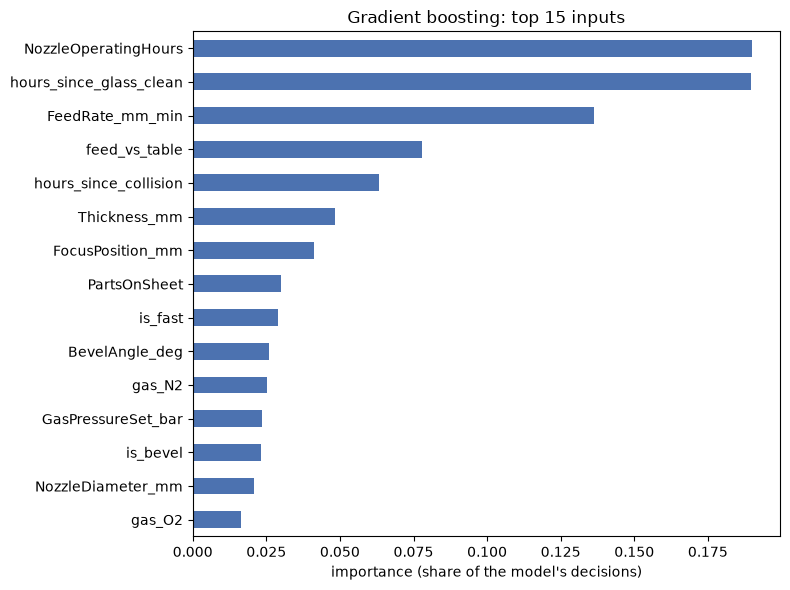

NozzleOperatingHours       0.190
hours_since_glass_clean    0.190
FeedRate_mm_min            0.136
feed_vs_table              0.078
hours_since_collision      0.063
Thickness_mm               0.048
FocusPosition_mm           0.041
PartsOnSheet               0.030
is_fast                    0.029
BevelAngle_deg             0.026
dtype: float64

In [11]:
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
top = imp.tail(15)

fig, ax = plt.subplots(figsize=(8, 6))
top.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("importance (share of the model's decisions)")
ax.set_title("Gradient boosting: top 15 inputs")
plt.tight_layout()
plt.savefig(FIG / "fig2_feature_importance.png", dpi=200)
plt.show()
imp.sort_values(ascending=False).head(10).round(3)

### Figure 3: does the model agree with the EDA? (nozzle hours vs defect)
A quick look at the strongest number column: if nozzle wear causes dross and rough cuts, those jobs should sit at higher nozzle hours.

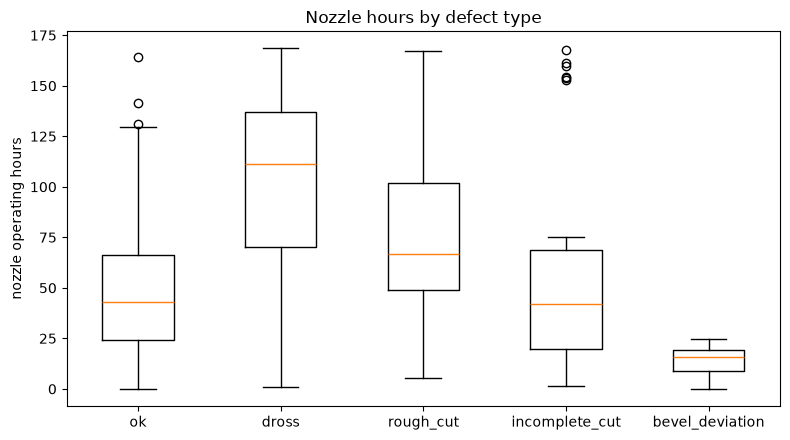

In [12]:
order = ["ok", "dross", "rough_cut", "incomplete_cut", "bevel_deviation"]
data = [jobs.loc[labelled & (jobs["defect"] == d), "NozzleOperatingHours"] for d in order]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(data, tick_labels=order)
ax.set_ylabel("nozzle operating hours")
ax.set_title("Nozzle hours by defect type")
plt.tight_layout()
plt.savefig(FIG / "fig3_nozzle_hours_by_defect.png", dpi=200)
plt.show()

## 10. A stricter test: train on the past, test on the future
In a real factory you train on old jobs and predict new ones. So here we train on jobs **before 26 Sep** and test on jobs **from 26 Sep on**.

Expect a **lower** score. Some causes (the head collision on 6 Oct, for example) never appear in the training period,
so the model has never seen a bevel problem caused by a collision. That's an honest limitation of a classical model, and a good argument for the knowledge graph:
the troubleshooting guide already *knows* what a collision does, even if the data hasn't shown it yet.

In [13]:
cut = pd.Timestamp("2026-09-26")
past = labelled & (jobs["StartTime"] < cut)
future = labelled & (jobs["StartTime"] >= cut)

time_model = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42)
time_model.fit(X_all[past], jobs.loc[past, "defect"])
time_pred = time_model.predict(X_all[future])
y_future = jobs.loc[future, "defect"]

print("train jobs:", past.sum(), "| test jobs:", future.sum())
print("defects seen in training:", sorted(jobs.loc[past, "defect"].unique()))
print(f"Always-'ok' baseline : {(y_future == 'ok').mean():.1%}")
print(f"Accuracy (time split): {accuracy_score(y_future, time_pred):.1%}")
print(f"Macro F1 (time split): {f1_score(y_future, time_pred, average='macro'):.2f}")

train jobs: 264 | test jobs: 137
defects seen in training: ['dross', 'incomplete_cut', 'ok', 'rough_cut']
Always-'ok' baseline : 51.8%
Accuracy (time split): 69.3%
Macro F1 (time split): 0.53


### Figure 4: the three scores side by side

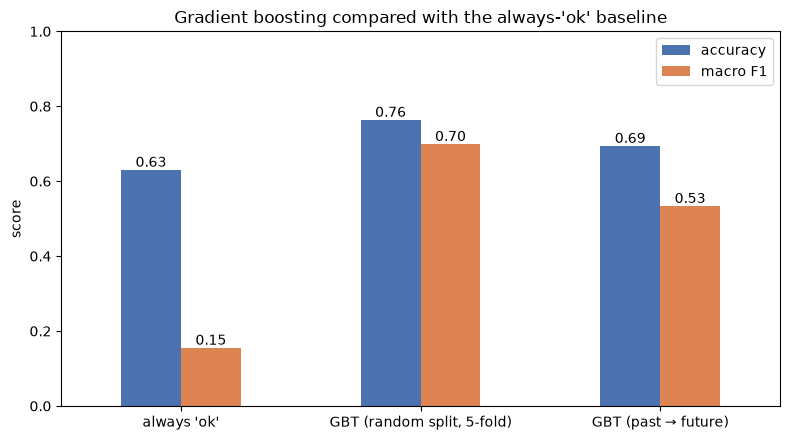

,accuracy,macro F1
always 'ok',0.630,0.155
"GBT (random split, 5-fold)",0.763,0.699
GBT (past → future),0.693,0.533


In [14]:
scores = pd.DataFrame({
    "accuracy": [baseline, cv_acc.mean(), accuracy_score(y_future, time_pred)],
    "macro F1": [f1_score(y_test, ["ok"] * len(y_test), average="macro"), cv_f1.mean(), f1_score(y_future, time_pred, average="macro")],
}, index=["always 'ok'", "GBT (random split, 5-fold)", "GBT (past → future)"])

ax = scores.plot(kind="bar", figsize=(8, 4.5), rot=0, color=["#4C72B0", "#DD8452"])
ax.set_ylim(0, 1)
ax.set_ylabel("score")
ax.set_title("Gradient boosting compared with the always-'ok' baseline")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
plt.tight_layout()
plt.savefig(FIG / "fig4_scores.png", dpi=200)
plt.show()
scores.round(3)

## What this notebook showed
- The **master job table** is the job log plus columns built from your EDA findings. It's saved as `master_job_table.csv`.
- Gradient boosting predicts the defect much better than always guessing `ok`. The confusion matrix shows which defects it still mixes up.
- **Feature importance** checks the model against your EDA: the top inputs should measure the causes you found.
- **Past → future** testing is harder, because a classical model can't predict a cause it has never seen. Use this in the report as the motivation for the knowledge graph + LLM.

**For the report (Chapter 5):** figures 1 to 4 are in `data/processed/figures/`. Report the 5-fold mean ± spread, not one lucky split.

**Next:** turn the timeline into the **knowledge graph**, then compare the graph + LLM answers against `answer_key_jobs.csv` and against this baseline.